In [1]:
# ============================================================
# 1. LIBRERÍAS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.stats.api as sms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

from scipy import stats

In [3]:
# ============================================================
# 2. CARGAR LA BASE DE DATOS
# ============================================================

df = pd.read_csv("Cientifico de datos M53 - Advertising.csv")

print("Dimensiones de la base:", df.shape)
display(df.head())
print("\nInformación de las variables:")
print(df.info())

Dimensiones de la base: (200, 4)


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9



Información de las variables:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB
None


In [5]:
# ============================================================
# 3. ESTADÍSTICAS DESCRIPTIVAS
# ============================================================

display(df.describe())

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


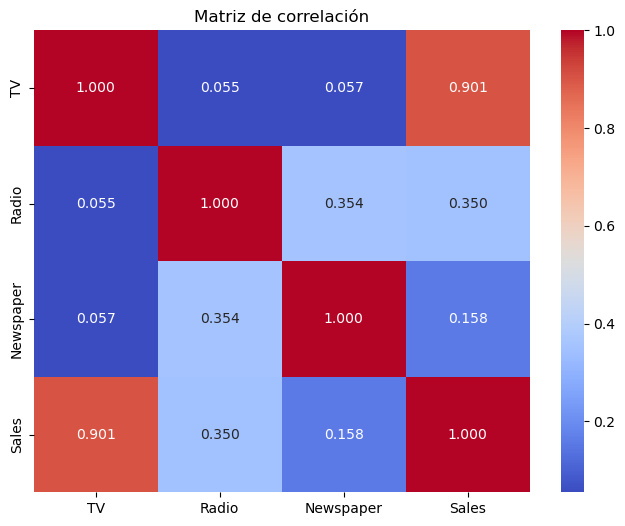

In [7]:
# ============================================================
# 4. MATRIZ DE CORRELACIÓN
# ============================================================

plt.figure(figsize=(8,6))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".3f"
)

plt.title("Matriz de correlación")
plt.show()

In [9]:
# ============================================================
# 5. VARIABLES INDEPENDIENTES Y DEPENDIENTE
# ============================================================

X = df[["TV", "Radio", "Newspaper"]]
y = df["Sales"]

# 70% entrenamiento / 30% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (140, 3)
Datos de prueba: (60, 3)


In [11]:
# ============================================================
# 6. MODELO INICIAL
# ============================================================

X_train_const = sm.add_constant(X_train)

modelo_inicial = sm.OLS(
    y_train,
    X_train_const
).fit()

print(modelo_inicial.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.897
Method:                 Least Squares   F-statistic:                     405.2
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           1.36e-67
Time:                        18:22:10   Log-Likelihood:                -272.35
No. Observations:                 140   AIC:                             552.7
Df Residuals:                     136   BIC:                             564.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6614      0.368     12.650      0.0

In [13]:
# ============================================================
# 7. MODELO FINAL
# ============================================================

X_train_final = X_train[["TV", "Radio"]]

X_train_final_const = sm.add_constant(X_train_final)

modelo_final = sm.OLS(
    y_train,
    X_train_final_const
).fit()

print(modelo_final.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.898
Method:                 Least Squares   F-statistic:                     612.0
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           4.95e-69
Time:                        18:22:28   Log-Likelihood:                -272.37
No. Observations:                 140   AIC:                             550.7
Df Residuals:                     137   BIC:                             559.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6390      0.350     13.240      0.0

In [15]:
# ============================================================
# 8. CALIDAD DEL AJUSTE
# ============================================================

print("R²:", modelo_final.rsquared)
print("R² ajustado:", modelo_final.rsquared_adj)
print("F-statistic:", modelo_final.fvalue)
print("p-value del modelo:", modelo_final.f_pvalue)

R²: 0.8993439479032659
R² ajustado: 0.8978745164857953
F-statistic: 612.0353336744128
p-value del modelo: 4.949173107744684e-69


In [17]:
# ============================================================
# 9. PREDICCIONES SOBRE EL GRUPO DE PRUEBA
# ============================================================

X_test_final = X_test[["TV", "Radio"]]

X_test_final_const = sm.add_constant(
    X_test_final,
    has_constant="add"
)

y_pred = modelo_final.predict(X_test_final_const)

r2_test = r2_score(y_test, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_test, y_pred)
)

mae = mean_absolute_error(y_test, y_pred)

print("R² en entrenamiento:", modelo_final.rsquared)
print("R² en prueba:", r2_test)
print("RMSE:", rmse)
print("MAE:", mae)

R² en entrenamiento: 0.8993439479032659
R² en prueba: 0.9073562242286407
RMSE: 1.5376953350310447
MAE: 1.1919753277836762


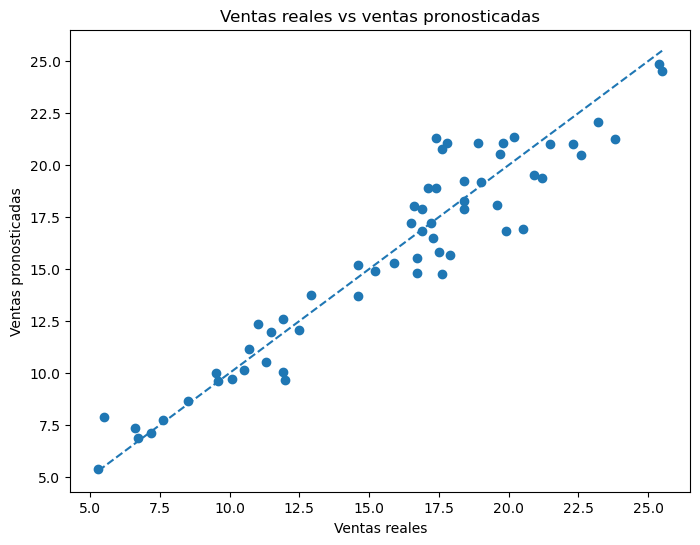

In [19]:
# ============================================================
# 10. REAL VS PREDICHO
# ============================================================

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Ventas reales")
plt.ylabel("Ventas pronosticadas")
plt.title("Ventas reales vs ventas pronosticadas")

# Línea ideal
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.show()

In [21]:
# ============================================================
# 11. PREDICCIÓN PARA TV=100 Y RADIO=50
# ============================================================

nuevo = pd.DataFrame({
    "const": [1],
    "TV": [100],
    "Radio": [50]
})

prediccion = modelo_final.get_prediction(nuevo)

resultado = prediccion.summary_frame(alpha=0.10)

display(resultado)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,15.221676,0.304019,14.718204,15.725147,12.342813,18.100538


In [23]:
# ============================================================
# 12. INTERVALO DE CONFIANZA DEL 90%
# ============================================================

print("Predicción:", resultado["mean"].iloc[0])

print(
    "Intervalo de confianza del 90%:",
    resultado["mean_ci_lower"].iloc[0],
    "a",
    resultado["mean_ci_upper"].iloc[0]
)

print(
    "Intervalo de predicción del 90%:",
    resultado["obs_ci_lower"].iloc[0],
    "a",
    resultado["obs_ci_upper"].iloc[0]
)

Predicción: 15.221675664877203
Intervalo de confianza del 90%: 14.718204466534416 a 15.72514686321999
Intervalo de predicción del 90%: 12.342813225960844 a 18.10053810379356


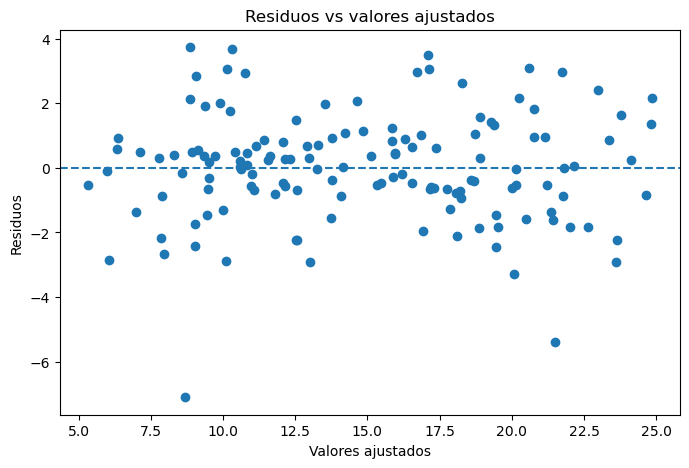

In [25]:
# ============================================================
# 13. RESIDUOS
# ============================================================

residuos = modelo_final.resid
ajustados = modelo_final.fittedvalues

plt.figure(figsize=(8,5))

plt.scatter(ajustados, residuos)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Valores ajustados")
plt.ylabel("Residuos")
plt.title("Residuos vs valores ajustados")

plt.show()

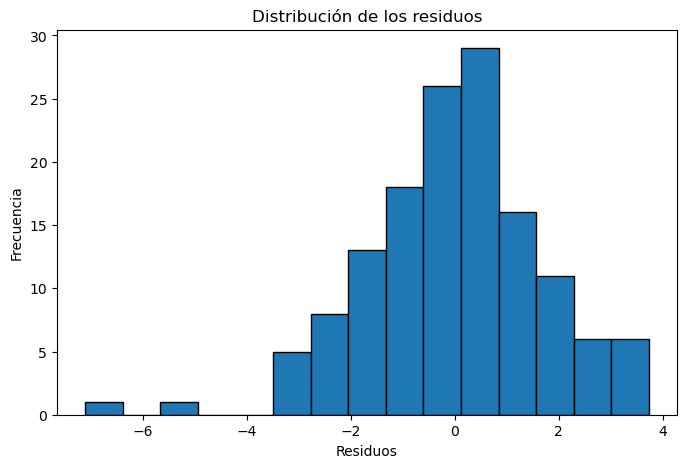

In [27]:
# ============================================================
# 14. HISTOGRAMA DE RESIDUOS
# ============================================================

plt.figure(figsize=(8,5))

plt.hist(
    residuos,
    bins=15,
    edgecolor="black"
)

plt.xlabel("Residuos")
plt.ylabel("Frecuencia")
plt.title("Distribución de los residuos")

plt.show()

In [29]:
# ============================================================
# 15. PRUEBA JARQUE-BERA
# ============================================================

jb = stats.jarque_bera(residuos)

print("Estadístico Jarque-Bera:", jb.statistic)
print("p-value:", jb.pvalue)

Estadístico Jarque-Bera: 24.662861496030988
p-value: 4.410904674141444e-06


In [31]:
# ============================================================
# 16. SESGO Y CURTOSIS CON SCIPY
# ============================================================

sesgo_python = stats.skew(residuos, bias=False)

curtosis_python = stats.kurtosis(
    residuos,
    fisher=True,
    bias=False
)

print("Sesgo:", sesgo_python)
print("Curtosis:", curtosis_python)

Sesgo: -0.5179846546969996
Curtosis: 1.8920445337904672


In [33]:
# ============================================================
# 17. FUNCIÓN MANUAL PARA SESGO
# ============================================================

def sesgo_manual(x):
    x = np.array(x)
    
    n = len(x)
    media = np.mean(x)
    
    desviacion = np.sqrt(
        np.sum((x - media)**2) / (n - 1)
    )
    
    g1 = (
        (n / ((n-1)*(n-2)))
        *
        np.sum(
            ((x - media) / desviacion)**3
        )
    )
    
    return g1


sesgo_manual_resultado = sesgo_manual(residuos)

print("Sesgo Python :", sesgo_python)
print("Sesgo manual :", sesgo_manual_resultado)

Sesgo Python : -0.5179846546969996
Sesgo manual : -0.5179846546969997


In [35]:
# ============================================================
# 18. FUNCIÓN MANUAL PARA CURTOSIS
# ============================================================

def curtosis_manual(x):
    x = np.array(x)
    
    n = len(x)
    media = np.mean(x)
    
    s = np.std(x, ddof=1)
    
    k = (
        (n*(n+1))
        /
        ((n-1)*(n-2)*(n-3))
    ) * np.sum(
        ((x-media)/s)**4
    )
    
    k = k - (
        3*(n-1)**2
        /
        ((n-2)*(n-3))
    )
    
    return k


curtosis_manual_resultado = curtosis_manual(residuos)

print("Curtosis Python :", curtosis_python)
print("Curtosis manual :", curtosis_manual_resultado)

Curtosis Python : 1.8920445337904672
Curtosis manual : 1.8920445337904663


In [37]:
# ============================================================
# 19. DURBIN-WATSON CON STATSMODELS
# ============================================================

dw_python = sms.durbin_watson(residuos)

print("Durbin-Watson:", dw_python)

Durbin-Watson: 2.0375161916374998


In [39]:
# ============================================================
# 20. DURBIN-WATSON MANUAL
# ============================================================

def durbin_watson_manual(residuos):
    
    residuos = np.array(residuos)
    
    numerador = np.sum(
        np.diff(residuos)**2
    )
    
    denominador = np.sum(
        residuos**2
    )
    
    return numerador / denominador


dw_manual = durbin_watson_manual(residuos)

print("Durbin-Watson Python :", dw_python)
print("Durbin-Watson manual :", dw_manual)

Durbin-Watson Python : 2.0375161916374998
Durbin-Watson manual : 2.0375161916374998


In [41]:
# ============================================================
# 21. PRUEBA DE WHITE
# ============================================================

white_test = sms.het_white(
    residuos,
    modelo_final.model.exog
)

lm_stat = white_test[0]
lm_pvalue = white_test[1]
f_stat = white_test[2]
f_pvalue = white_test[3]

print("LM Statistic:", lm_stat)
print("LM p-value:", lm_pvalue)
print("F Statistic:", f_stat)
print("F p-value:", f_pvalue)

LM Statistic: 11.353378151633706
LM p-value: 0.04480664163871973
F Statistic: 2.3651653661175978
F p-value: 0.04301479079659278


In [43]:
# ============================================================
# 22. PRUEBA DE WHITE MANUAL
# ============================================================

def white_manual(modelo, X):
    
    residuos = modelo.resid
    e2 = residuos**2
    
    X = X[["TV", "Radio"]].copy()
    
    # Términos de la regresión auxiliar
    X_aux = pd.DataFrame({
        "TV": X["TV"],
        "Radio": X["Radio"],
        "TV2": X["TV"]**2,
        "Radio2": X["Radio"]**2,
        "TV_Radio": X["TV"] * X["Radio"]
    })
    
    X_aux = sm.add_constant(X_aux)
    
    modelo_aux = sm.OLS(
        e2,
        X_aux
    ).fit()
    
    R2 = modelo_aux.rsquared
    n = len(X)
    
    LM = n * R2
    
    # grados de libertad:
    # número de variables explicativas auxiliares
    gl = X_aux.shape[1] - 1
    
    p_value = 1 - stats.chi2.cdf(
        LM,
        gl
    )
    
    return LM, p_value, modelo_aux


LM_manual, p_manual, modelo_aux = white_manual(
    modelo_final,
    X_train
)

print("White LM manual:", LM_manual)
print("p-value manual:", p_manual)

White LM manual: 11.353378151633706
p-value manual: 0.044806641638719724


In [45]:
# ============================================================
# 23. RESUMEN DE SUPUESTOS
# ============================================================

alpha = 0.10

print("==========================================")
print("       RESUMEN DEL MODELO FINAL")
print("==========================================")

print("\n1. NORMALIDAD")
print("p-value Jarque-Bera:", jb.pvalue)

if jb.pvalue > alpha:
    print("Conclusión: NO se rechaza normalidad.")
else:
    print("Conclusión: Se rechaza normalidad.")

print("\n2. AUTOCORRELACIÓN")
print("Durbin-Watson:", dw_python)

if 1.5 < dw_python < 2.5:
    print("Conclusión: No se observa autocorrelación importante.")
else:
    print("Conclusión: Puede existir autocorrelación.")

print("\n3. HETEROCEDASTICIDAD")
print("p-value White:", lm_pvalue)

if lm_pvalue > alpha:
    print("Conclusión: No se rechaza homocedasticidad.")
else:
    print("Conclusión: Existe evidencia de heterocedasticidad.")

print("\n4. SESGO")
print("Sesgo:", sesgo_python)

print("\n5. CURTOSIS")
print("Curtosis:", curtosis_python)

print("\n6. R²")
print("R² entrenamiento:", modelo_final.rsquared)
print("R² prueba:", r2_test)

       RESUMEN DEL MODELO FINAL

1. NORMALIDAD
p-value Jarque-Bera: 4.410904674141444e-06
Conclusión: Se rechaza normalidad.

2. AUTOCORRELACIÓN
Durbin-Watson: 2.0375161916374998
Conclusión: No se observa autocorrelación importante.

3. HETEROCEDASTICIDAD
p-value White: 0.04480664163871973
Conclusión: Existe evidencia de heterocedasticidad.

4. SESGO
Sesgo: -0.5179846546969996

5. CURTOSIS
Curtosis: 1.8920445337904672

6. R²
R² entrenamiento: 0.8993439479032659
R² prueba: 0.9073562242286407
